Rodrigo Baptista - ist1114851
João Silva - ist1113812

In [18]:
# imports e dados

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import shap
from sklearn.feature_selection import f_classif
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

df = pd.read_csv("breast_cancer.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(569, 31)
['diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [19]:
# separar X e y

target_col = "diagnosis"         

y = df[target_col]
X = df.drop(columns=[target_col])

# remove colunas que não são features
drop_cols = [c for c in X.columns if c.lower() == "id" or c.lower().startswith("unnamed")]
X = X.drop(columns=drop_cols)
X = X.select_dtypes(include=[np.number])

print("X:", X.shape)          
print(y.value_counts())       

X: (569, 30)
diagnosis
B    357
M    212
Name: count, dtype: int64


In [20]:
# II.1
# F-statistic e p-value

F, p = f_classif(X, y)

ranking = (pd.DataFrame({"feature": X.columns, "F": F, "p_value": p})
             .sort_values("F", ascending=False)
             .reset_index(drop=True))
ranking.index += 1   # ranking começa em 1
display(ranking)

selected = ranking.loc[ranking["p_value"] <= 0.05, "feature"].tolist()
removed  = ranking.loc[ranking["p_value"] > 0.05, "feature"].tolist()

print("Mantidas:", len(selected))
print("Removidas (p > 0.05):", removed)

X_sel = X[selected]

,feature,F,p_value
1,concave points_worst,964.385393,1.969100e-124
2,perimeter_worst,897.944219,5.771397e-119
3,concave points_mean,861.676020,7.101150e-116
4,radius_worst,860.781707,8.482292e-116
5,perimeter_mean,697.235272,8.436251e-101
6,area_worst,661.600206,2.828848e-97
7,radius_mean,646.981021,8.465941e-96
8,area_mean,573.060747,4.734564e-88
9,concavity_mean,533.793126,9.966556e-84
10,concavity_worst,436.691939,2.464664e-72


Mantidas: 25
Removidas (p > 0.05): ['fractal_dimension_se', 'smoothness_se', 'fractal_dimension_mean', 'texture_se', 'symmetry_se']


In [21]:
# II.2
# split e treino das 6 árvores

X_train, X_test, y_train, y_test = train_test_split(
    X_sel, y, test_size=0.2, stratify=y, random_state=1
)

min_splits = [2, 5, 10, 20, 50, 100]
train_acc, test_acc, models = {}, {}, {}

for m in min_splits:
    clf = DecisionTreeClassifier(min_samples_split=m, random_state=1)
    clf.fit(X_train, y_train)
    models[m] = clf
    train_acc[m] = accuracy_score(y_train, clf.predict(X_train))
    test_acc[m]  = accuracy_score(y_test,  clf.predict(X_test))

results = pd.DataFrame({"min_samples_split": min_splits,
                        "train_acc": [train_acc[m] for m in min_splits],
                        "test_acc":  [test_acc[m]  for m in min_splits]})
display(results)

,min_samples_split,train_acc,test_acc
0,2,1.000000,0.921053
1,5,0.997802,0.921053
2,10,0.993407,0.929825
3,20,0.989011,0.929825
4,50,0.958242,0.885965
5,100,0.958242,0.885965


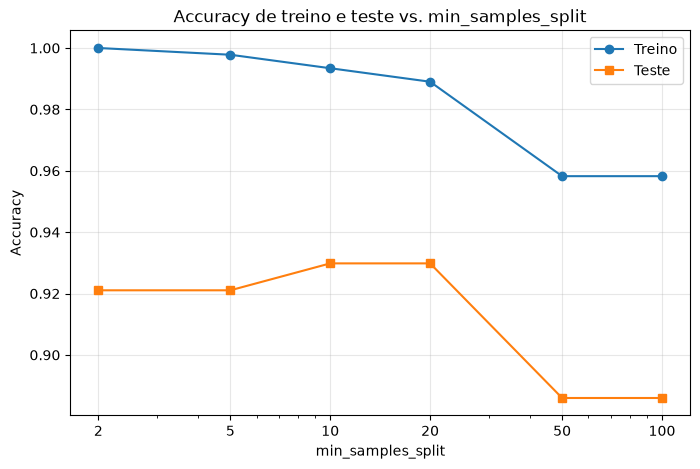

In [22]:
# II.2
# gráfico único treino vs teste

plt.figure(figsize=(8, 5))
plt.plot(min_splits, [train_acc[m] for m in min_splits], "o-", label="Treino")
plt.plot(min_splits, [test_acc[m] for m in min_splits], "s-", label="Teste")
plt.xscale("log")
plt.xticks(min_splits, [str(m) for m in min_splits])
plt.xlabel("min_samples_split")
plt.ylabel("Accuracy")
plt.title("Accuracy de treino e teste vs. min_samples_split")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Melhor min_samples_split: 20 | treino: 0.989 | teste: 0.9298


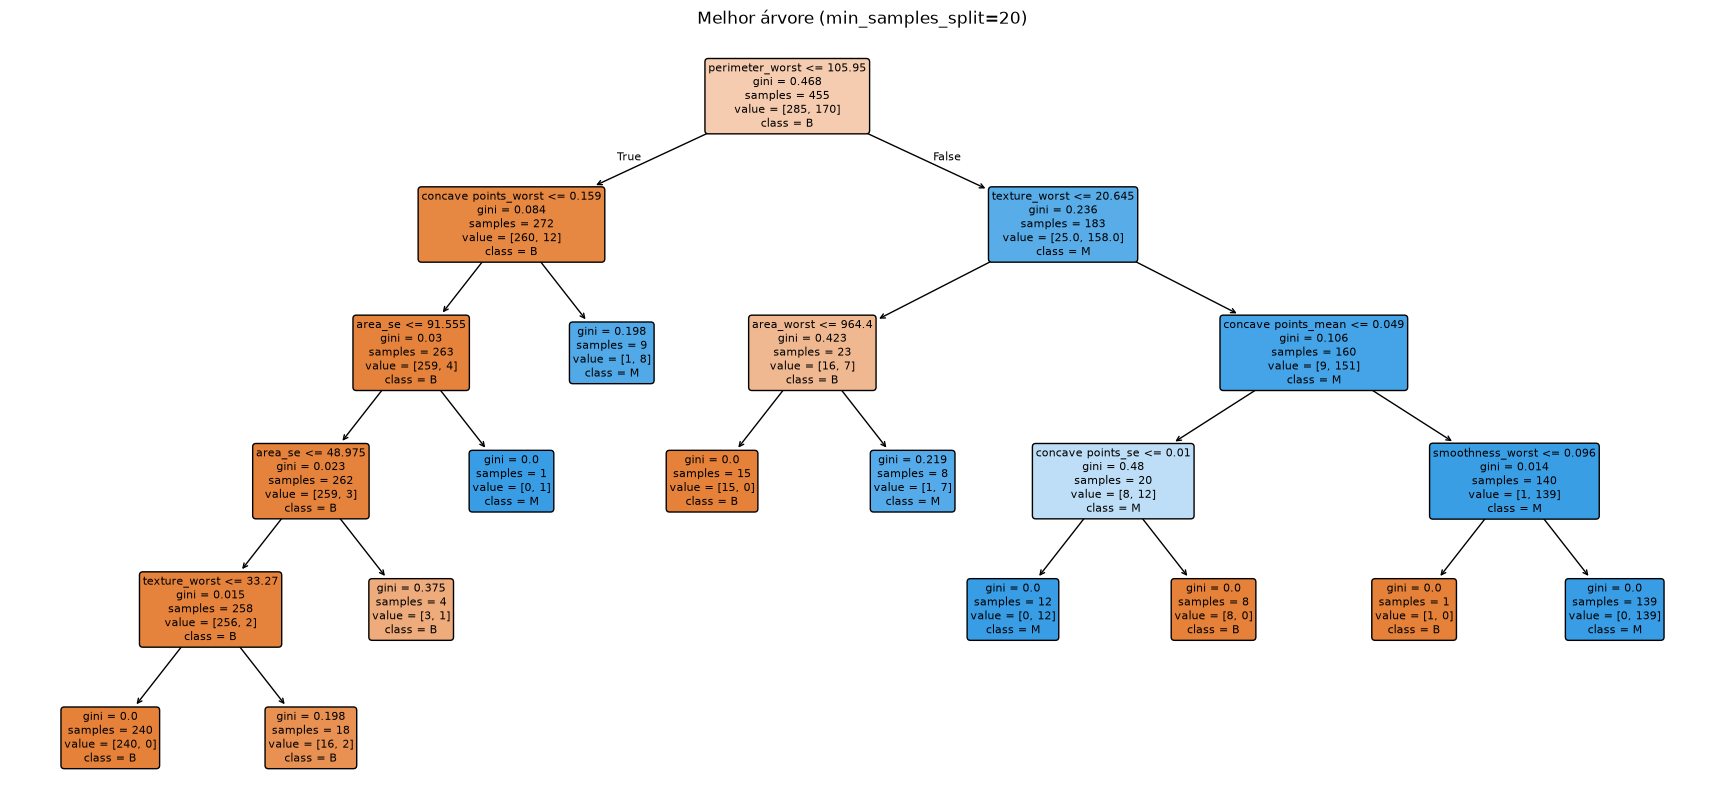

In [23]:
# II.2
# melhor árvore e gráfico da árvore

# melhor accuracy de teste; em empate, maior min_samples_split
best_m = max(min_splits, key=lambda m: (test_acc[m], m))
best_model = models[best_m]
print("Melhor min_samples_split:", best_m,
      "| treino:", round(train_acc[best_m], 4),
      "| teste:", round(test_acc[best_m], 4))

plt.figure(figsize=(22, 10))
plot_tree(best_model, feature_names=selected,
          class_names=list(best_model.classes_),
          filled=True, rounded=True, fontsize=8)
plt.title(f"Melhor árvore (min_samples_split={best_m})")
plt.show()

# II.3

Com min_samples_split baixo (2 e 5), a árvore ajusta-se quase na perfeição ao treino (100% e 99,8%), mas tem 92,1% no teste, o que indica overfitting. Com valores intermédios (10 e 20), a árvore é mais simples e generaliza melhor: o teste sobe para 92,98% e a diferença treino-teste é menor, sendo min_samples_split = 20 o melhor compromisso. Com valores mais altos (50 e 100), a árvore fica demasiado restrita e a accuracy desce em ambos os conjuntos (95,8% no treino e 88,6% no teste), o que indica underfitting. Para além disso, pode-se considerar que o conjunto de teste não é muito grande, pelo que diferenças de uma ou duas amostras não devem ter muito peso estatístico.

# II.4

Recomendamos o Modelo B (precision 88%, recall 98%). Num rastreio inicial, o mais importante é não deixar escapar doentes: um falso negativo (tumor maligno classificado benigno) atrasa o diagnóstico e o tratamento, com consequências graves. Já um falso positivo apenas leva a exames adicionais, com algum custo e ansiedade, mas o erro é corrigido na avaliação clínica seguinte. Como o modelo só decide quem é encaminhado para avaliação e não faz o diagnóstico final, é aceitável sacrificar alguma precision para maximizar o recall. O Modelo A, com recall de 88%, deixaria passar cerca de 12% dos casos malignos, o que é inaceitável num contexto de rastreio.

In [24]:
# II.5
# SHAP

explainer = shap.TreeExplainer(best_model)
sv = explainer(X_test)
print(sv.values.shape)

# índice da classe maligna (M)
idx_M = list(best_model.classes_).index("M")
sv_M = sv[:, :, idx_M]

(114, 25, 2)


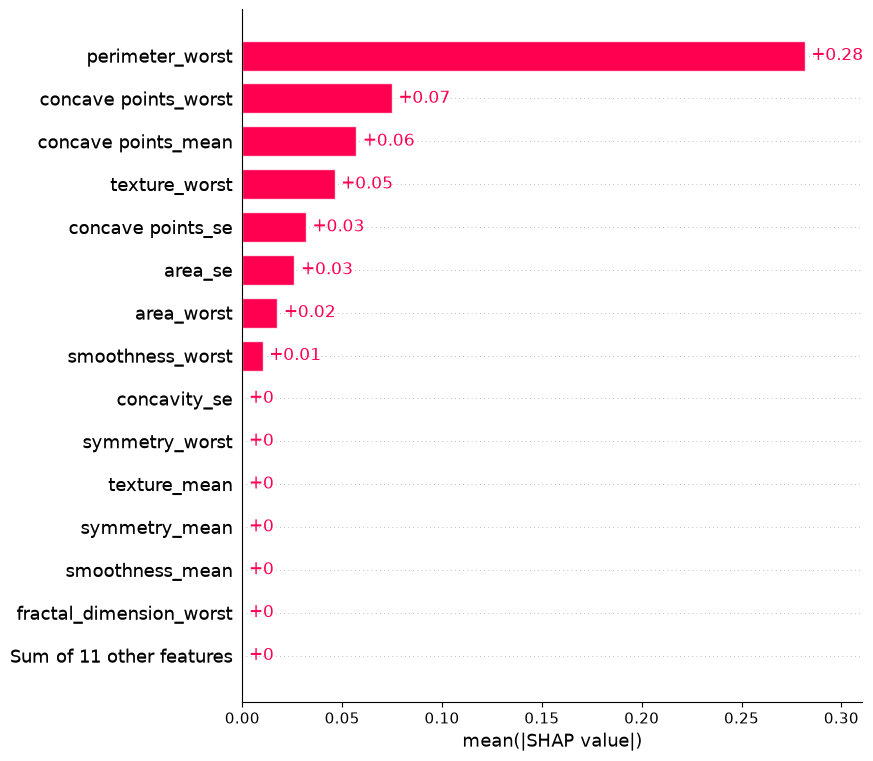

perimeter_worst         0.281623
concave points_worst    0.074831
concave points_mean     0.057010
texture_worst           0.046186
concave points_se       0.031837
dtype: float64
Top 2: ['perimeter_worst', 'concave points_worst']


In [25]:
# II.5a
# gráfico de barras

shap.plots.bar(sv_M, max_display=15)

mean_abs = pd.Series(np.abs(sv_M.values).mean(axis=0), index=selected).sort_values(ascending=False)
print(mean_abs.head(5))
top2 = mean_abs.index[:2].tolist()
print("Top 2:", top2)

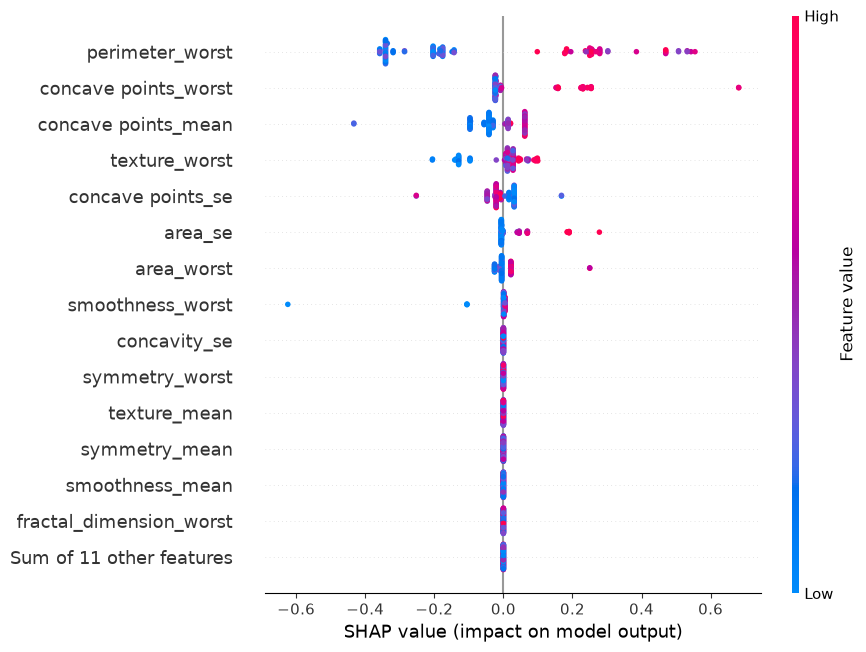

In [26]:
# II.5b
# beeswarm

shap.plots.beeswarm(sv_M, max_display=15)